GPU INFERENCE EXECUTION AND BOTTLENECK IDENTIFICATION

SYSTEM INFORMATION
----------------------------------------
Operating System: Linux
Processor: x86_64
PyTorch Version: 2.14.1+cpu
Selected Device: cpu
GPU not available. Running on CPU.

MODEL INFORMATION
----------------------------------------
CNNModel(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(i

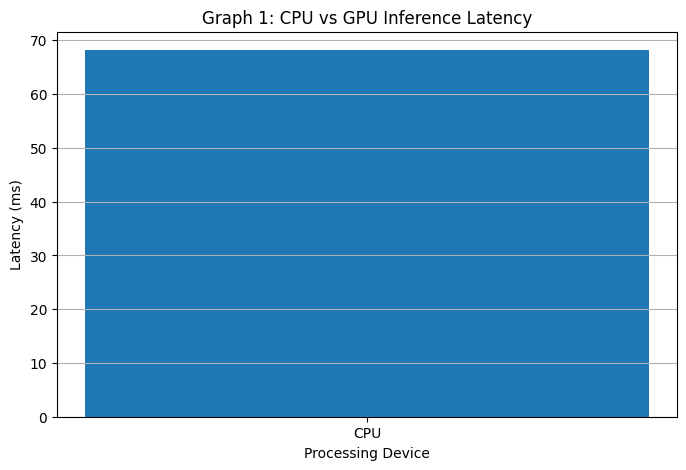

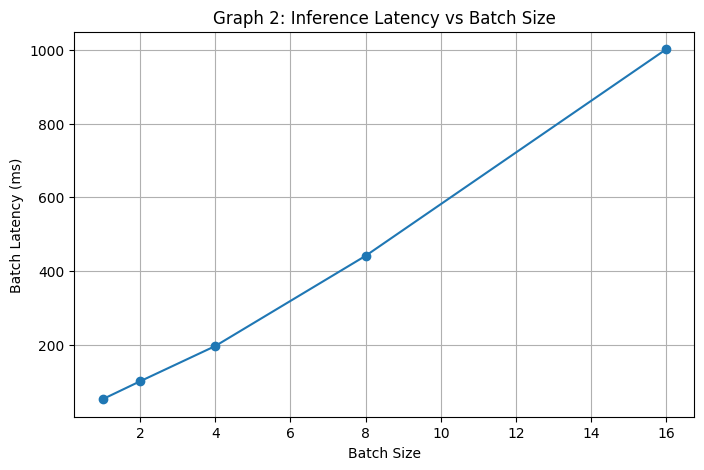

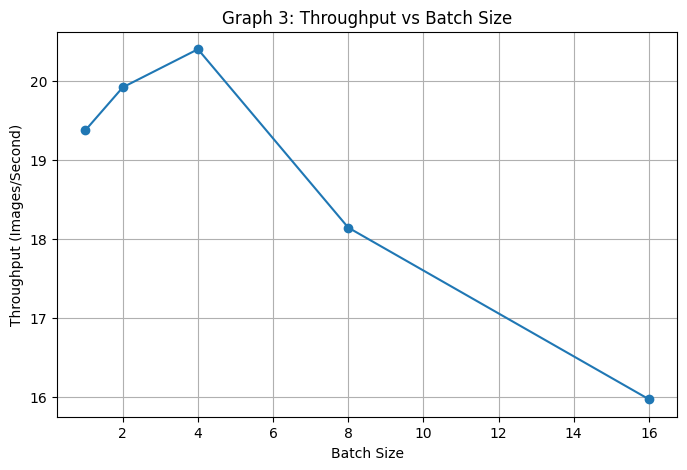

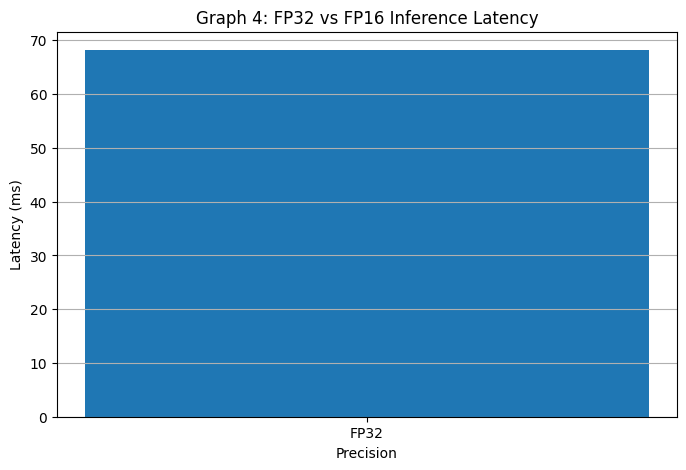

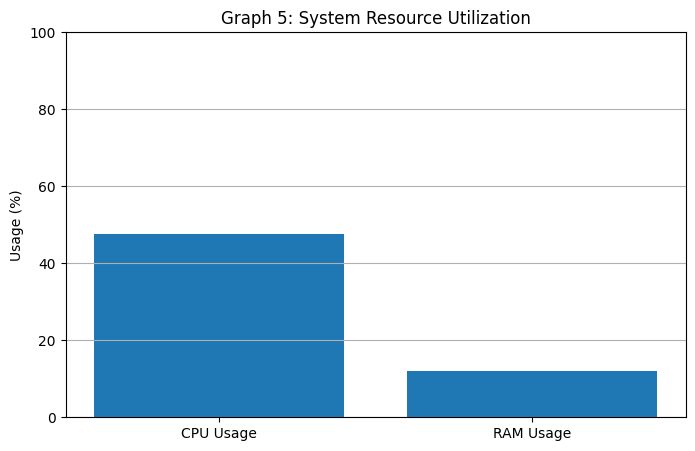

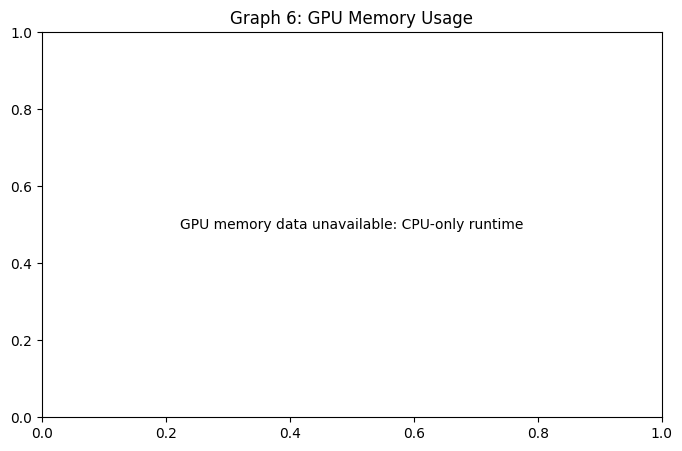



FINAL EXPERIMENT RESULTS
CPU Inference Latency : 68.188 ms
GPU Results           : Not available
CPU Utilization       : 47.70%
RAM Utilization       : 12.00%
Best Tested Batch Size: 4
Best Tested Throughput: 20.40 images/sec

EXPERIMENT COMPLETED SUCCESSFULLY
Six graph sections have been executed.


In [5]:

# ============================================================
# DEEP LEARNING SKILL LAB
# GPU Inference Execution Path and System-Level Bottleneck
# Identification
#
# Complete Google Colab experiment with 6 graphs
# ============================================================

# STEP 1: INSTALL AND IMPORT LIBRARIES

!pip -q install psutil

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import psutil
import time
import platform
import subprocess
import gc

from IPython.display import display

print("=" * 60)
print("GPU INFERENCE EXECUTION AND BOTTLENECK IDENTIFICATION")
print("=" * 60)

# STEP 2: SYSTEM INFORMATION

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("\nSYSTEM INFORMATION")
print("-" * 40)
print("Operating System:", platform.system())
print("Processor:", platform.processor())
print("PyTorch Version:", torch.__version__)
print("Selected Device:", device)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
else:
    print("GPU not available. Running on CPU.")

# STEP 3: DEFINE CNN MODEL

class CNNModel(nn.Module):

    def __init__(self):
        super(CNNModel, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# STEP 4: CREATE MODEL AND INPUT DATA

model = CNNModel()
model.eval()

input_data = torch.randn(1, 3, 224, 224)

print("\nMODEL INFORMATION")
print("-" * 40)
print(model)

# STEP 5: CPU INFERENCE BENCHMARK

print("\nCPU INFERENCE TEST")
print("-" * 40)

cpu_model = model.to("cpu")
cpu_input = input_data.to("cpu")

with torch.no_grad():
    for _ in range(5):
        cpu_model(cpu_input)

cpu_times = []

with torch.no_grad():
    for _ in range(30):
        start = time.perf_counter()
        cpu_model(cpu_input)
        end = time.perf_counter()

        cpu_times.append((end - start) * 1000)

cpu_latency = np.mean(cpu_times)

print(f"CPU Inference Latency: {cpu_latency:.3f} ms")

# STEP 6: GPU INFERENCE BENCHMARK

gpu_available = torch.cuda.is_available()

gpu_latency = None
gpu_times = []
batch_sizes = []
latencies = []
throughputs = []
transfer_time = None
fp16_latency = None

allocated = 0
reserved = 0
peak = 0

if gpu_available:

    print("\nGPU INFERENCE TEST")
    print("-" * 40)

    gpu_model = model.to(device)
    gpu_input = input_data.to(device)

    def synchronize():
        torch.cuda.synchronize()

    with torch.no_grad():

        for _ in range(10):
            gpu_model(gpu_input)

        synchronize()

        for _ in range(50):

            synchronize()
            start = time.perf_counter()

            gpu_model(gpu_input)

            synchronize()
            end = time.perf_counter()

            gpu_times.append((end - start) * 1000)

    gpu_latency = np.mean(gpu_times)

    print(f"GPU Inference Latency: {gpu_latency:.3f} ms")

    # STEP 7: CPU TO GPU DATA TRANSFER TIME

    print("\nDATA TRANSFER TEST")
    print("-" * 40)

    transfer_times = []

    with torch.no_grad():

        for _ in range(50):

            synchronize()
            start = time.perf_counter()

            transferred = input_data.to(device)

            synchronize()
            end = time.perf_counter()

            transfer_times.append((end - start) * 1000)

    transfer_time = np.mean(transfer_times)

    print(f"CPU to GPU Transfer Time: {transfer_time:.3f} ms")

    # STEP 8: BATCH SIZE PERFORMANCE TEST

    print("\nBATCH SIZE PERFORMANCE TEST")
    print("-" * 40)

    batch_sizes_to_test = [1, 2, 4, 8, 16, 32]

    for batch in batch_sizes_to_test:

        try:
            batch_input = torch.randn(
                batch, 3, 224, 224,
                device=device
            )

            with torch.no_grad():

                for _ in range(5):
                    gpu_model(batch_input)

                synchronize()

                times = []

                for _ in range(20):

                    synchronize()
                    start = time.perf_counter()

                    gpu_model(batch_input)

                    synchronize()
                    end = time.perf_counter()

                    times.append((end - start) * 1000)

            avg_latency = np.mean(times)
            throughput = (batch * 1000) / avg_latency

            batch_sizes.append(batch)
            latencies.append(avg_latency)
            throughputs.append(throughput)

            print(
                f"Batch {batch:2d} | "
                f"Latency: {avg_latency:.3f} ms | "
                f"Throughput: {throughput:.2f} images/sec"
            )

            del batch_input
            gc.collect()

        except RuntimeError as error:
            print(f"Batch {batch} skipped:", str(error)[:150])
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    # STEP 9: FP32 VS FP16 TEST

    print("\nFP32 VS FP16 TEST")
    print("-" * 40)

    try:

        fp16_model = CNNModel().to(device).half().eval()
        fp16_input = input_data.to(device).half()

        with torch.no_grad():

            for _ in range(10):
                fp16_model(fp16_input)

            synchronize()

            fp16_times = []

            for _ in range(50):

                synchronize()
                start = time.perf_counter()

                fp16_model(fp16_input)

                synchronize()
                end = time.perf_counter()

                fp16_times.append((end - start) * 1000)

        fp16_latency = np.mean(fp16_times)

        print(f"FP32 Latency: {gpu_latency:.3f} ms")
        print(f"FP16 Latency: {fp16_latency:.3f} ms")

        del fp16_model, fp16_input

    except Exception as error:
        print("FP16 test unavailable:", error)

    # STEP 10: GPU MEMORY INFORMATION

    torch.cuda.synchronize()

    allocated = torch.cuda.memory_allocated(0) / (1024 ** 2)
    reserved = torch.cuda.memory_reserved(0) / (1024 ** 2)
    peak = torch.cuda.max_memory_allocated(0) / (1024 ** 2)

    print("\nGPU MEMORY INFORMATION")
    print("-" * 40)
    print(f"Allocated Memory: {allocated:.2f} MB")
    print(f"Reserved Memory: {reserved:.2f} MB")
    print(f"Peak Memory: {peak:.2f} MB")

else:

    print("\nGPU tests skipped because CUDA is unavailable.")

    # CPU batch tests provide useful fallback measurements.
    print("\nCPU BATCH SIZE PERFORMANCE TEST")

    for batch in [1, 2, 4, 8, 16]:

        try:
            batch_input = torch.randn(batch, 3, 224, 224)

            with torch.no_grad():

                for _ in range(3):
                    cpu_model(batch_input)

                times = []

                for _ in range(10):
                    start = time.perf_counter()
                    cpu_model(batch_input)
                    end = time.perf_counter()

                    times.append((end - start) * 1000)

            avg_latency = np.mean(times)
            throughput = (batch * 1000) / avg_latency

            batch_sizes.append(batch)
            latencies.append(avg_latency)
            throughputs.append(throughput)

            print(
                f"Batch {batch:2d} | "
                f"Latency: {avg_latency:.3f} ms | "
                f"Throughput: {throughput:.2f} images/sec"
            )

        except Exception as error:
            print(f"Batch {batch} skipped:", error)


# STEP 11: SYSTEM RESOURCE MONITORING

cpu_usage = psutil.cpu_percent(interval=1)
ram_usage = psutil.virtual_memory().percent

print("\nSYSTEM RESOURCE UTILIZATION")
print("-" * 40)
print(f"CPU Usage: {cpu_usage:.2f}%")
print(f"RAM Usage: {ram_usage:.2f}%")

# STEP 12: BOTTLENECK IDENTIFICATION

print("\nBOTTLENECK ANALYSIS")
print("-" * 40)

if gpu_available:

    print(f"CPU Latency: {cpu_latency:.3f} ms")
    print(f"GPU Latency: {gpu_latency:.3f} ms")
    print(f"Data Transfer Time: {transfer_time:.3f} ms")

    speedup = cpu_latency / gpu_latency

    print(f"GPU Speedup: {speedup:.2f}x")

    if transfer_time > gpu_latency:
        print("Possible Bottleneck: CPU-GPU Data Transfer")
    elif gpu_latency > cpu_latency:
        print("Observation: GPU is not faster for this workload.")
        print("Possible causes include small workload or GPU overhead.")
    else:
        print("Observation: GPU inference is faster than CPU inference.")

    if cpu_usage > 80:
        print("High CPU utilization detected.")

    if ram_usage > 80:
        print("High RAM utilization detected.")

else:

    speedup = None
    print("GPU bottleneck analysis unavailable in CPU-only mode.")
    print("Use a GPU-enabled Colab runtime for GPU analysis.")


# STEP 13: DISPLAY ALL SIX GRAPHS

print("\n")
print("=" * 60)
print("GENERATING SIX PERFORMANCE GRAPHS")
print("=" * 60)


# GRAPH 1: CPU VS GPU LATENCY

plt.figure(figsize=(8, 5))

labels = ["CPU"]
values = [cpu_latency]

if gpu_available:
    labels.append("GPU")
    values.append(gpu_latency)

plt.bar(labels, values)
plt.title("Graph 1: CPU vs GPU Inference Latency")
plt.xlabel("Processing Device")
plt.ylabel("Latency (ms)")
plt.grid(axis="y")
plt.show()


# GRAPH 2: LATENCY VS BATCH SIZE

plt.figure(figsize=(8, 5))

if len(batch_sizes) > 0:
    plt.plot(batch_sizes, latencies, marker="o")
    plt.xlabel("Batch Size")
    plt.ylabel("Batch Latency (ms)")
    plt.title("Graph 2: Inference Latency vs Batch Size")
    plt.grid(True)
else:
    plt.text(0.5, 0.5, "Batch measurements unavailable",
             ha="center", va="center")

plt.show()


# GRAPH 3: THROUGHPUT VS BATCH SIZE

plt.figure(figsize=(8, 5))

if len(batch_sizes) > 0:
    plt.plot(batch_sizes, throughputs, marker="o")
    plt.xlabel("Batch Size")
    plt.ylabel("Throughput (Images/Second)")
    plt.title("Graph 3: Throughput vs Batch Size")
    plt.grid(True)
else:
    plt.text(0.5, 0.5, "Throughput measurements unavailable",
             ha="center", va="center")

plt.show()


# GRAPH 4: FP32 VS FP16 LATENCY

plt.figure(figsize=(8, 5))

precision_labels = ["FP32"]
precision_values = [gpu_latency if gpu_available else cpu_latency]

if fp16_latency is not None:
    precision_labels.append("FP16")
    precision_values.append(fp16_latency)

plt.bar(precision_labels, precision_values)
plt.title("Graph 4: FP32 vs FP16 Inference Latency")
plt.xlabel("Precision")
plt.ylabel("Latency (ms)")
plt.grid(axis="y")
plt.show()


# GRAPH 5: CPU AND RAM UTILIZATION

plt.figure(figsize=(8, 5))

plt.bar(
    ["CPU Usage", "RAM Usage"],
    [cpu_usage, ram_usage]
)

plt.title("Graph 5: System Resource Utilization")
plt.ylabel("Usage (%)")
plt.ylim(0, 100)
plt.grid(axis="y")
plt.show()


# GRAPH 6: GPU MEMORY USAGE

plt.figure(figsize=(8, 5))

if gpu_available:
    plt.bar(
        ["Allocated", "Reserved", "Peak"],
        [allocated, reserved, peak]
    )
    plt.title("Graph 6: GPU Memory Usage")
    plt.ylabel("Memory (MB)")
    plt.grid(axis="y")
else:
    plt.text(
        0.5, 0.5,
        "GPU memory data unavailable: CPU-only runtime",
        ha="center", va="center"
    )
    plt.title("Graph 6: GPU Memory Usage")

plt.show()


# STEP 14: FINAL RESULTS

print("\n")
print("=" * 60)
print("FINAL EXPERIMENT RESULTS")
print("=" * 60)

print(f"CPU Inference Latency : {cpu_latency:.3f} ms")

if gpu_available:

    print(f"GPU Inference Latency : {gpu_latency:.3f} ms")
    print(f"GPU Speedup           : {speedup:.2f}x")
    print(f"Data Transfer Time    : {transfer_time:.3f} ms")

    if fp16_latency is not None:
        print(f"FP16 Inference Latency: {fp16_latency:.3f} ms")

    print(f"GPU Allocated Memory  : {allocated:.2f} MB")
    print(f"GPU Reserved Memory   : {reserved:.2f} MB")

else:
    print("GPU Results           : Not available")

print(f"CPU Utilization       : {cpu_usage:.2f}%")
print(f"RAM Utilization       : {ram_usage:.2f}%")

if len(batch_sizes) > 0:
    best_index = int(np.argmax(throughputs))
    print(f"Best Tested Batch Size: {batch_sizes[best_index]}")
    print(f"Best Tested Throughput: {throughputs[best_index]:.2f} images/sec")

print("\nEXPERIMENT COMPLETED SUCCESSFULLY")
print("Six graph sections have been executed.")
